# EOS transformation to a table with entropy on axis 1

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')

In [4]:
import dispatch
import dispatch.EOS
from dispatch.EOS import deriv,interp,integral

## Tomida & Hori (2016) EOS

The ``dispatch.EOS.open()`` method (source code in ``utilities/python/dispatch/EOS/_EOS.py``) knows where to find the data tables, if the ``top`` directory is specified (or -- alternatively -- the environment variable ``DISPATCH`` is set to the top directory):

In [5]:
eos=dispatch.EOS.open('tomida',top=top)
eos.variables

{0: 'ln(P)', 1: 'ln(E)', 2: 'ln(C_T)', 3: 'ln(cs)', 4: 'gamma', 5: 'ln(Cv)'}

Density scale range:

In [6]:
s0=eos.scale0
s0.print()

ln(rho): min=     -50.7 step:     0.115    o:0  n:461 max:       2.3


In [7]:
print('min(rho)={:.2e}  max(rho)={:.2e}'.format(np.exp(s0.min),np.exp(s0.max)))

min(rho)=1.00e-22  max(rho)=1.00e+01


Compute array with inconsistency measure:

In [8]:
c=np.zeros((eos.scale0.n,eos.scale1.n))
for i in range(1,eos.scale0.n-1):
    c[i,:]=dispatch.EOS.inconsistency(eos,i)

#### Get JCD model S data

In [9]:
from dispatch.solar_models import JCD_S
model=JCD_S(top=top)

Get ``(log(rho),log(E))``

In [10]:
def model_S(eos):
    """ Return (log10(rho), log10(E)), where rho[i] is from JCD model S, and
        E is from the EOS enegy E[i] that corresponds to T[i] from the model.
    """
    s0=eos.scale0
    vars=eos.variables.values()
    ln10=np.log(10.0)
    LogE=[]
    LogD=[]
    for i,rho in enumerate(model.rho):
        Ti=model.T[i]
        lnd=np.log(rho)
        if lnd < s0.max:
            ir,p=s0.index(lnd)
            if ir<s0.n:
                lnT,lnE=eos.values(ir,'ln(E)')
                lnTi=np.log(Ti)
                j=np.where(lnT>lnTi)[0]
                if len(j)>1:
                    j=max(j[0]-2,0)
                    lnT=lnT[j:]
                    lnE=lnE[j:]
                    log_d=np.log10(rho)
                    log_E=interp(lnT,lnE,lnTi)/ln10
                    LogE.append(log_E)
                    LogD.append(log_d)
    return np.array(LogD),np.array(LogE)

Compute and plot log10(rho),log10(T) for Model S

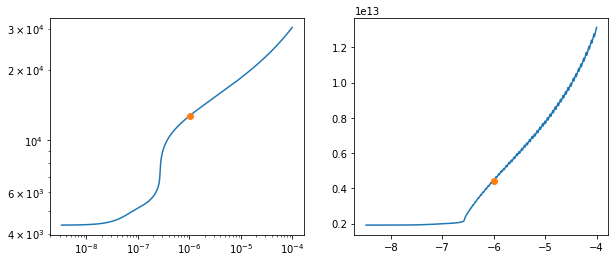

In [11]:
model=dispatch.solar_models.JCD_S(top=top)

pl.figure(figsize=(10,4))
pl.subplot(1,2,1)
w=np.where(model.rho<1e-4)[0]
pl.loglog(model.rho[w],model.T[w]);
w=np.where(model.rho>1e-6)[0][0]
rho,T=model.rho[w],model.T[w]
pl.loglog(rho,T,'o')

logD,logE=model_S(eos)
pl.subplot(1,2,2)
w=np.where(10**logD<1e-4)[0]
pl.plot(logD[w],10.**logE[w]);
lnr=np.log(rho)
lnE=eos.lookup('ln(E)',lnr,np.log(T))
E=np.exp(lnE)
pl.plot(lnr/np.log(10),E,'o');

### Display inconsistencies, with Model S overlay

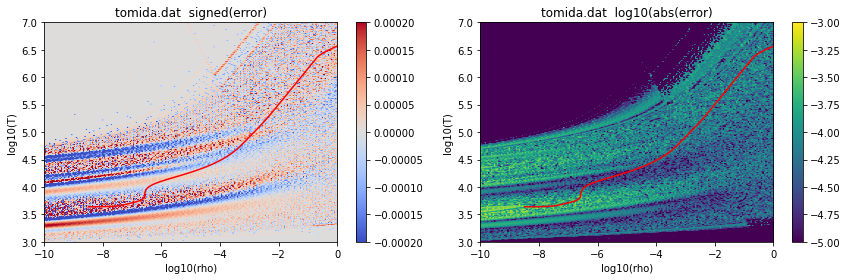

In [12]:
pl.figure(figsize=(12,4))
for i in (0,1):
    pl.subplot(1,2,1+i)
    T=eos.scale1.values
    lnd=eos.scale0.values
    ln10=np.log(10)
    vmax=0.02
    e=(eos.scale0.min/ln10,eos.scale0.max/ln10,eos.scale1.min/ln10,eos.scale1.max/ln10)
    w=np.where(model.rho<10.)[0]
    if i:
        cl=np.log10(np.abs(c)+1e-10)
        pl.imshow(cl.T,vmin=-5,vmax=-3,extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  log10(abs(error)')
    else:
        vmax=2e-4
        pl.imshow(c.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
        pl.title(eos.file+'  signed(error)')
    pl.xlabel('log10(rho)'); pl.ylabel('log10(T)')
    pl.colorbar()
    pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
    pl.xlim(-10,0); pl.ylim(3,7);
pl.tight_layout()

A single vertical cut:

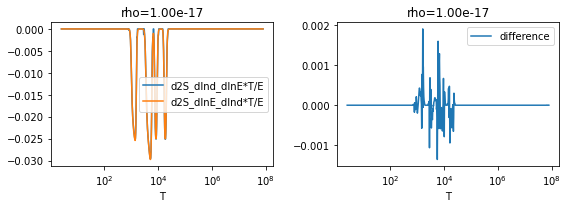

In [13]:
dispatch.EOS.inconsistency(eos,100,plot=1);

### Conversion to a table based on $(\ln\rho,S)$

Read in the original Tomida & Horis EOS, which uses $(\ln\rho,\ln T)$ as independent variables

In [14]:
eos=dispatch.EOS.open('tomida',top=top)

Convert to $(\ln\rho,S)$ as independent variables, using the method ``lnT_to_S()``, with source code in ``EOS/tomida.py`` (under ``utilities/python/dispatch/``):

In [15]:
new=eos.lnT_to_S(verbose=1)

S: min= -1.84e+09 step:  9.27e+06    o:0  n:1000 max:  7.41e+09
variables: {0: 'ln(P)', 1: 'ln(E)', 2: 'ln(C_T)', 3: 'ln(cs)', 4: 'gamma', 5: 'ln(Cv)', 6: 'ln(T)'}


Show an image of the ``ln(T)`` entry (converted to log10() along with x-axis for plotting) --cf. ``imdhow`` source code in ``EOS/irregular_tables.py``

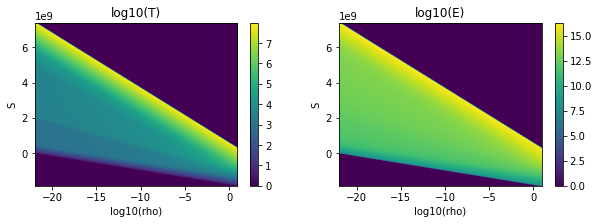

In [16]:
pl.figure(figsize=(10,3))
pl.subplot(1,2,1); new.imshow('ln(T)');
pl.subplot(1,2,2); new.imshow('ln(E)');

An adiabat at S=0 extends through the whole table:

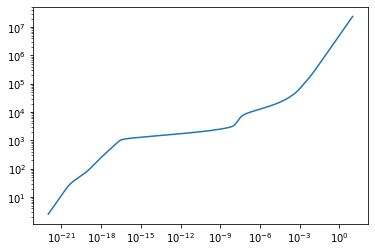

In [17]:
Tadia=[]
for i in range(new.scale0.n):
    S,lnT=new.values(i,'ln(T)')
    Tadia.append(np.exp(dispatch.EOS.interp(S,lnT,0.0)))
pl.loglog(np.exp(lnd),Tadia);

Overplot the adiabat on the image with Model S:

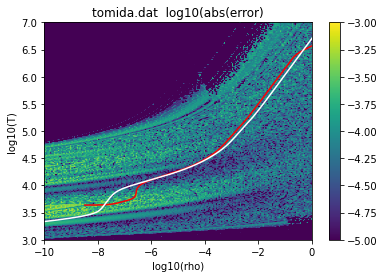

In [18]:
pl.imshow(cl.T,vmin=-5,vmax=-3,extent=e,aspect='auto',origin='lower')
pl.title(eos.file+'  log10(abs(error)')
pl.xlabel('log10(rho)'); pl.ylabel('log10(T)')
pl.colorbar()
pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
pl.plot(lnd/ln10,np.log10(Tadia),color='w')
pl.xlim(-10,0); pl.ylim(3,7);